# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

Taakverdeling

- Token indicators: IDS
- Bag-of-words: JULIUS
- extra of your choice: IDS


- log-linear: JULIUS
- single-hidden-layer MLP: IDS
- extra: JULIUS

In [2]:
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [3]:
from datasets import load_dataset
from collections import Counter
import numpy as np
import pandas as pd
from tokenizers import Tokenizer

In [4]:
# load and inspect dataset
ds = load_dataset("gsri-18/ISEAR-dataset-complete")

print(ds)
train = ds["train"]

emotions = train.unique("emotion")

print("Unique emotions:", emotions)
print("Number of emotions:", len(emotions))

# Count samples per emotion
print("\nEmotion distribution:")
print(Counter(train["emotion"]))

DatasetDict({
    train: Dataset({
        features: ['emotion', 'content', 'Unnamed: 2'],
        num_rows: 7516
    })
})
Unique emotions: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
Number of emotions: 7

Emotion distribution:
Counter({'joy': 1092, 'sadness': 1082, 'anger': 1079, 'fear': 1076, 'shame': 1071, 'disgust': 1066, 'guilt': 1050})


## BPE tokenizer (from tutorial)

In [5]:
vocab_size = 1000
min_frequency = 2

tokenizer = part1.experiment.train_tokenizer(train["content"], vocab_size, min_frequency)
tokenizer.save(f"results/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")
vocab = tokenizer.get_vocab()

# **Bag of Words**

In [6]:
file_name = "results/BPE_tokenizer_vs_1000_mf_2.json"
tokenizer = Tokenizer.from_file(file_name)
vocab = tokenizer.get_vocab()

In [7]:
def bag_of_words(text, tokenizer, vocab_size):

    # tokenize the text
    encoding = tokenizer.encode(text)
    tokens = encoding.tokens
    token_ids = encoding.ids

    # create an empty vector
    vector = np.zeros(vocab_size)

    # loop through token IDs and count occurrences
    for ids in token_ids:
        vector[ids] += 1

    return vector

## Train/test split maken

In [8]:
from sklearn.model_selection import train_test_split

df = ds["train"].to_pandas()

X = df["content"].tolist()
y = df["emotion"].tolist()

# 70% training, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

print(df.shape)
print("Training:", len(X_train))
print("Test:", len(X_test))

(7516, 3)
Training: 5261
Test: 2255


## *Representation spaces on whole dataset*

In [9]:
# usES BoW on whole dataset

X_train_BoW = np.array([bag_of_words(text, tokenizer, tokenizer.get_vocab_size())
    for text in X_train])

X_test_BoW = np.array([bag_of_words(text, tokenizer, tokenizer.get_vocab_size())
    for text in X_test])

print(X_train_BoW.shape)
print(X_test_BoW.shape)

(5261, 1000)
(2255, 1000)


In [10]:
encoder = part1.classifier.encoder_indicator()

X_train_indicator = np.array([encoder(text)
    for text in X_train])

X_test_indicator = np.array([encoder(text)
    for text in X_test])

print(X_train_indicator.shape)
print(X_test_indicator.shape)

(5261, 1000)
(2255, 1000)


In [11]:
encoder = part1.classifier.encoder_tf_idf()

X_train_tf_idf = np.array([encoder(text)
    for text in X_train])

X_test_tf_idf = np.array([encoder(text)
    for text in X_test])

print(X_train_tf_idf.shape)
print(X_test_tf_idf.shape)

(5261, 1000)
(2255, 1000)


# **log-linear**

In [12]:
from sklearn.linear_model import LogisticRegression

loglinear_BoW = LogisticRegression(max_iter=1000, random_state=42)
loglinear_indicator = LogisticRegression(max_iter=1000, random_state=42)
loglinear_tf_idf = LogisticRegression(max_iter=1000, random_state=42)

# loglinear for Bag of Words, indicator and tf_idf
loglinear_BoW.fit(X_train_BoW, y_train)
loglinear_indicator.fit(X_train_indicator, y_train)
loglinear_tf_idf.fit(X_train_tf_idf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## *evaluate BoW, Indicator and TF-IDF with Log-linear* 

In [13]:
from sklearn.metrics import accuracy_score, classification_report

y_test_pred_BoW = loglinear_BoW.predict(X_test_BoW)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_BoW))
print(classification_report(y_test, y_test_pred_BoW))

Test accuracy: 0.49623059866962305
              precision    recall  f1-score   support

       anger       0.38      0.40      0.39       324
     disgust       0.52      0.47      0.49       320
        fear       0.59      0.61      0.60       323
       guilt       0.44      0.41      0.42       315
         joy       0.60      0.66      0.63       328
     sadness       0.57      0.55      0.56       324
       shame       0.37      0.38      0.37       321

    accuracy                           0.50      2255
   macro avg       0.49      0.50      0.49      2255
weighted avg       0.50      0.50      0.50      2255



In [14]:
y_test_pred_indicator = loglinear_indicator.predict(X_test_indicator)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_indicator))
print(classification_report(y_test, y_test_pred_indicator))

Test accuracy: 0.5015521064301552
              precision    recall  f1-score   support

       anger       0.41      0.42      0.41       324
     disgust       0.51      0.47      0.49       320
        fear       0.61      0.62      0.61       323
       guilt       0.44      0.41      0.43       315
         joy       0.60      0.66      0.63       328
     sadness       0.56      0.54      0.55       324
       shame       0.37      0.38      0.37       321

    accuracy                           0.50      2255
   macro avg       0.50      0.50      0.50      2255
weighted avg       0.50      0.50      0.50      2255



In [15]:
y_test_pred_tf_idf = loglinear_tf_idf.predict(X_test_tf_idf)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_tf_idf))
print(classification_report(y_test, y_test_pred_tf_idf))

Test accuracy: 0.47982261640798224
              precision    recall  f1-score   support

       anger       0.38      0.37      0.37       324
     disgust       0.44      0.45      0.44       320
        fear       0.59      0.59      0.59       323
       guilt       0.40      0.39      0.39       315
         joy       0.60      0.66      0.63       328
     sadness       0.55      0.53      0.54       324
       shame       0.38      0.36      0.37       321

    accuracy                           0.48      2255
   macro avg       0.48      0.48      0.48      2255
weighted avg       0.48      0.48      0.48      2255



# *MLP with single hidden layer*

In [16]:
from sklearn.neural_network import MLPClassifier

mlp_BoW = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)
mlp_indicator = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)
mlp_tf_idf = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)

# Train the model
mlp_BoW.fit(X_train_BoW, y_train)
mlp_indicator.fit(X_train_indicator, y_train)
mlp_tf_idf.fit(X_train_tf_idf, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(50,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## *evaluate BoW, Indicator and TF-IDF with MLP* 

In [17]:
y_test_pred_MLP_BoW = mlp_BoW.predict(X_test_BoW)

print("MLP BoW test accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_BoW))

print(classification_report(y_test, y_test_pred_MLP_BoW))

MLP BoW test accuracy: 0.4842572062084257
              precision    recall  f1-score   support

       anger       0.40      0.40      0.40       324
     disgust       0.46      0.43      0.44       320
        fear       0.60      0.59      0.59       323
       guilt       0.40      0.40      0.40       315
         joy       0.62      0.66      0.64       328
     sadness       0.52      0.53      0.52       324
       shame       0.38      0.38      0.38       321

    accuracy                           0.48      2255
   macro avg       0.48      0.48      0.48      2255
weighted avg       0.48      0.48      0.48      2255



In [18]:
y_test_pred_MLP_indicator = mlp_indicator.predict(X_test_indicator)

print("MLP Indicator Test Accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_indicator))

print(classification_report(y_test, y_test_pred_MLP_indicator))

MLP Indicator Test Accuracy: 0.48337028824833705
              precision    recall  f1-score   support

       anger       0.38      0.36      0.37       324
     disgust       0.46      0.42      0.44       320
        fear       0.59      0.61      0.60       323
       guilt       0.42      0.41      0.41       315
         joy       0.59      0.66      0.62       328
     sadness       0.53      0.53      0.53       324
       shame       0.38      0.40      0.39       321

    accuracy                           0.48      2255
   macro avg       0.48      0.48      0.48      2255
weighted avg       0.48      0.48      0.48      2255



In [19]:
y_test_pred_MLP_tf_idf = mlp_tf_idf.predict(X_test_tf_idf)

print("MLP TF-IDF test accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_tf_idf))

print(classification_report(y_test, y_test_pred_MLP_tf_idf))

MLP TF-IDF test accuracy: 0.4842572062084257
              precision    recall  f1-score   support

       anger       0.37      0.34      0.35       324
     disgust       0.48      0.46      0.47       320
        fear       0.58      0.61      0.60       323
       guilt       0.40      0.40      0.40       315
         joy       0.64      0.66      0.65       328
     sadness       0.54      0.55      0.55       324
       shame       0.36      0.36      0.36       321

    accuracy                           0.48      2255
   macro avg       0.48      0.48      0.48      2255
weighted avg       0.48      0.48      0.48      2255



# **Random Forest (chosen model)**

In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest_BoW = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)
random_forest_indicator = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)
random_forest_tf_idf = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)

# random forest for Bag of Words, indicator and tf_idf
random_forest_BoW.fit(X_train_BoW, y_train)
random_forest_indicator.fit(X_train_indicator, y_train)
random_forest_tf_idf.fit(X_train_tf_idf, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## *evaluate BoW, Indicator and TF-IDF with Random forest* 

In [21]:
y_test_pred_RF_BoW = random_forest_BoW.predict(X_test_BoW)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_BoW))

print(classification_report(y_test, y_test_pred_RF_BoW))

Random Forest test accuracy: 0.5361419068736142
              precision    recall  f1-score   support

       anger       0.45      0.44      0.45       324
     disgust       0.54      0.54      0.54       320
        fear       0.61      0.66      0.64       323
       guilt       0.44      0.49      0.46       315
         joy       0.56      0.66      0.61       328
     sadness       0.68      0.55      0.61       324
       shame       0.48      0.40      0.44       321

    accuracy                           0.54      2255
   macro avg       0.54      0.54      0.53      2255
weighted avg       0.54      0.54      0.53      2255



In [22]:
y_test_pred_RF_indicator = random_forest_indicator.predict(X_test_indicator)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_indicator))

print(classification_report(y_test, y_test_pred_RF_indicator))

Random Forest test accuracy: 0.532150776053215
              precision    recall  f1-score   support

       anger       0.43      0.44      0.44       324
     disgust       0.51      0.54      0.53       320
        fear       0.56      0.63      0.59       323
       guilt       0.47      0.50      0.49       315
         joy       0.58      0.68      0.62       328
     sadness       0.67      0.54      0.60       324
       shame       0.51      0.38      0.44       321

    accuracy                           0.53      2255
   macro avg       0.53      0.53      0.53      2255
weighted avg       0.53      0.53      0.53      2255



In [23]:
y_test_pred_RF_tf_idf = random_forest_tf_idf.predict(X_test_tf_idf)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_tf_idf))

print(classification_report(y_test, y_test_pred_RF_tf_idf))

Random Forest test accuracy: 0.5290465631929047
              precision    recall  f1-score   support

       anger       0.44      0.45      0.45       324
     disgust       0.50      0.53      0.51       320
        fear       0.61      0.67      0.64       323
       guilt       0.46      0.48      0.47       315
         joy       0.58      0.67      0.62       328
     sadness       0.63      0.50      0.56       324
       shame       0.48      0.40      0.44       321

    accuracy                           0.53      2255
   macro avg       0.53      0.53      0.53      2255
weighted avg       0.53      0.53      0.53      2255



# *Cross-validation*

In [24]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def print_scores(scores):
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())

def run_cross_validation(model, X_train, y_train):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    print_scores(scores)

    return scores

In [25]:
scores_LR_BoW = run_cross_validation(LogisticRegression(max_iter=1000), X_train_BoW, y_train)
scores_LR_indicator = run_cross_validation(LogisticRegression(max_iter=1000), X_train_indicator, y_train)
scores_LR_tf_idf = run_cross_validation(LogisticRegression(max_iter=1000), X_train_tf_idf, y_train)

scores_MLP_BoW = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_BoW, y_train)
scores_MLP_indicator = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_indicator, y_train)
scores_MLP_tf_idf = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_tf_idf, y_train)

scores_RF_BoW = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_BoW, y_train)
scores_RF_indicator = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_indicator, y_train)
scores_RF_tf_idf = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_tf_idf, y_train)

Fold scores: [0.51282051 0.49239544 0.46673004 0.48098859 0.48954373]
Mean accuracy: 0.4884956614994637
Standard deviation: 0.01508710391642979
Fold scores: [0.5014245  0.48574144 0.48003802 0.49904943 0.50570342]
Mean accuracy: 0.49439136416322726
Standard deviation: 0.009797599290881748
Fold scores: [0.50332384 0.48669202 0.47813688 0.47053232 0.49809886]
Mean accuracy: 0.4873567825405595
Standard deviation: 0.012156069019644633
Fold scores: [0.48528015 0.48098859 0.45152091 0.46292776 0.46292776]
Mean accuracy: 0.4687290341916451
Standard deviation: 0.012551218089093711
Fold scores: [0.48148148 0.48574144 0.44961977 0.45912548 0.47718631]
Mean accuracy: 0.4706308970567526
Standard deviation: 0.013877171266598928
Fold scores: [0.48907882 0.49524715 0.47813688 0.47338403 0.51330798]
Mean accuracy: 0.4898309736079064
Standard deviation: 0.014059334617801806
Fold scores: [0.53181387 0.51901141 0.51806084 0.51806084 0.51235741]
Mean accuracy: 0.5198608718887554
Standard deviation: 0.0064

          Model  Mean accuracy  Standard deviation
    RF - TF-IDF         0.5391              0.0047
 RF - Indicator         0.5265              0.0089
       RF - BoW         0.5199              0.0064
 LR - Indicator         0.4944              0.0098
   MLP - TF-IDF         0.4898              0.0141
       LR - BoW         0.4885              0.0151
    LR - TF-IDF         0.4874              0.0122
MLP - Indicator         0.4706              0.0139
      MLP - BoW         0.4687              0.0126


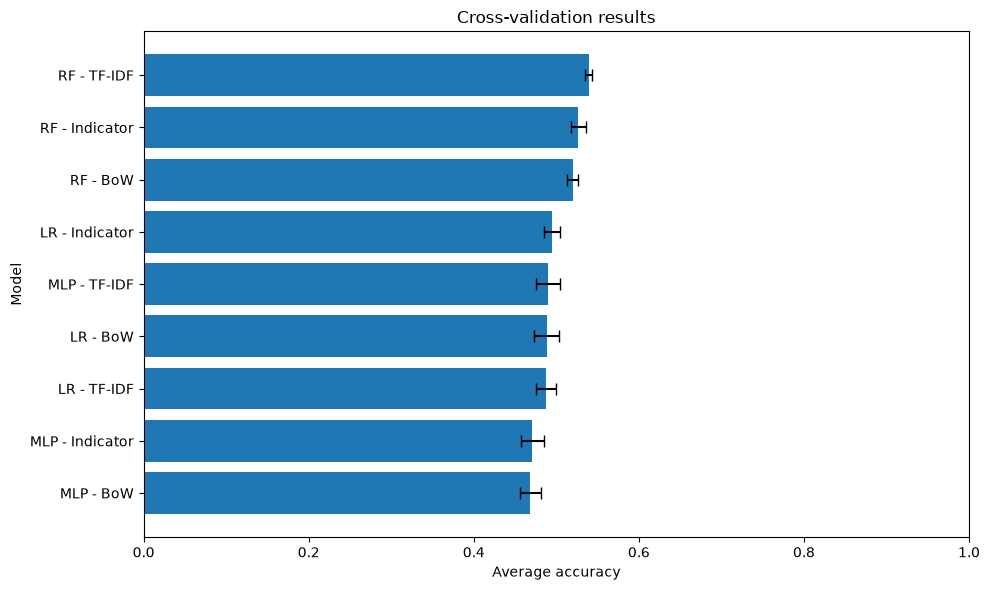

In [26]:
import matplotlib.pyplot as plt

# cross-validation scores together
results = {"LR - BoW": scores_LR_BoW,
    "LR - Indicator": scores_LR_indicator,
    "LR - TF-IDF": scores_LR_tf_idf,
    "MLP - BoW": scores_MLP_BoW,
    "MLP - Indicator": scores_MLP_indicator,
    "MLP - TF-IDF": scores_MLP_tf_idf,
    "RF - BoW": scores_RF_BoW,
    "RF - Indicator": scores_RF_indicator,
    "RF - TF-IDF": scores_RF_tf_idf}

# calculates average accuracy and standard deviation per model
summary = pd.DataFrame({"Model": results.keys(),
    "Mean accuracy": [np.mean(scores) for scores in results.values()],
    "Standard deviation": [np.std(scores) for scores in results.values()]})

# sorts models
summary = summary.sort_values("Mean accuracy", ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10, 6))
plt.barh(summary["Model"], summary["Mean accuracy"], xerr=summary["Standard deviation"], capsize=4)
plt.xlabel("Average accuracy")
plt.ylabel("Model")
plt.title("Cross-validation results")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# *region of practical equivalence (ROPE)*

In [28]:
import baycomp
from itertools import combinations

# cross-validation results
results = {"LR - BoW": scores_LR_BoW,
    "LR - Indicator": scores_LR_indicator,
    "LR - TF-IDF": scores_LR_tf_idf,
    "MLP - BoW": scores_MLP_BoW,
    "MLP - Indicator": scores_MLP_indicator,
    "MLP - TF-IDF": scores_MLP_tf_idf,
    "RF - BoW": scores_RF_BoW,
    "RF - Indicator": scores_RF_indicator,
    "RF - TF-IDF": scores_RF_tf_idf}

rope = 0.005
rope_results = []

# compare every pair of models
for model1, model2 in combinations(results.keys(), 2):
    probs = baycomp.two_on_single(results[model1], results[model2],
        rope=rope)

    p_left, p_rope, p_right = probs

    rope_results.append({"Model 1": model1,
        "Model 2": model2,
        "P(Model 1 better)": p_left,
        "P(Equivalent)": p_rope,
        "P(Model 2 better)": p_right})

rope_summary = pd.DataFrame(rope_results)
print("Bayesian comparison using ROPE = 0.005")
print(rope_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Bayesian comparison using ROPE = 0.005
        Model 1         Model 2  P(Model 1 better)  P(Equivalent)  P(Model 2 better)
       LR - BoW  LR - Indicator             0.1526         0.3112             0.5361
       LR - BoW     LR - TF-IDF             0.3040         0.4827             0.2134
       LR - BoW       MLP - BoW             0.9820         0.0148             0.0032
       LR - BoW MLP - Indicator             0.9444         0.0444             0.0112
       LR - BoW    MLP - TF-IDF             0.3150         0.2959             0.3891
       LR - BoW        RF - BoW             0.0071         0.0126             0.9803
       LR - BoW  RF - Indicator             0.0007         0.0013             0.9980
       LR - BoW     RF - TF-IDF             0.0020         0.0021             0.9959
 LR - Indicator     LR - TF-IDF             0.5894         0.2973             0.1133
 LR - Indicator       MLP - BoW             0.9427         0.0370             0.0203
 LR - Indicator MLP - Indi